# Praktikum 1 - Klasifikasi SVM dengan Data Dummy Linier

**Nama:** Mohammad Al Hafis Hidayatulloh  
**NIM:** 254107023005  
**Mata Kuliah:** RTI235004 - Pembelajaran Mesin  
**Dosen Pengampu:** Usman Nurhasan, S.Kom., M.T.

---

## Langkah 1 - Import Library

In [1]:
# import library
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import seaborn as sns

## Langkah 2 - Membuat Data Dummy

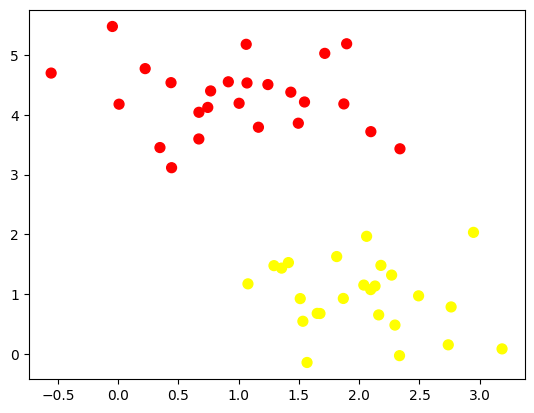

In [2]:
from sklearn.datasets import make_blobs

X, y = make_blobs(n_samples=50, centers=2,
                  random_state=0, cluster_std=0.60)
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
plt.show()

Data dummy yang dihasilkan `make_blobs` terdiri dari 50 titik dengan dua kelas yang terpisah cukup jelas. Satu kelompok berada di sisi kiri bawah dan kelompok lainnya di sisi kanan atas, dengan celah kosong di antara keduanya. `cluster_std=0.60` membuat sebaran tiap kelompok masih rapat, jadi secara visual sudah kelihatan bahwa kedua kelas bisa dipisahkan oleh sebuah garis lurus.

## Langkah 3 - Buat Ilustrasi Garis Pemisah

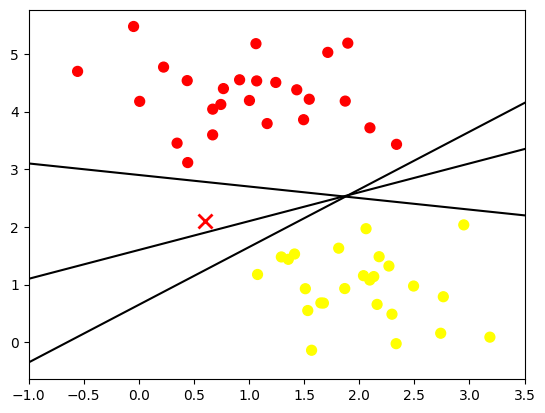

In [3]:
xfit = np.linspace(-1, 3.5)
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
# titik baru 'x' yang posisinya berada di antara dua kelompok
plt.plot([0.6], [2.1], 'x', color='red', markeredgewidth=2, markersize=10)

for m, b in [(1, 0.65), (0.5, 1.6), (-0.2, 2.9)]:
    plt.plot(xfit, m * xfit + b, '-k')

plt.xlim(-1, 3.5)
plt.show()

Pada gambar di atas saya menggambar tiga garis lurus yang berbeda dan ketiganya sama-sama memisahkan kedua kelas tanpa kesalahan pada data yang ada. Di sinilah masalahnya: kalau garis pemisah tidak unik, maka titik baru (tanda `x` merah) bisa diberi label yang berbeda tergantung garis mana yang dipakai. Titik tersebut berada di atas garis pertama dan kedua, tetapi di bawah garis ketiga, sehingga garis ketiga akan memberi label yang berlawanan dengan dua garis lainnya. Jadi, sekadar bisa memisahkan data latih belum cukup untuk menjamin prediksi yang konsisten pada data baru.

## Langkah 4 - Ilustrasi Margin

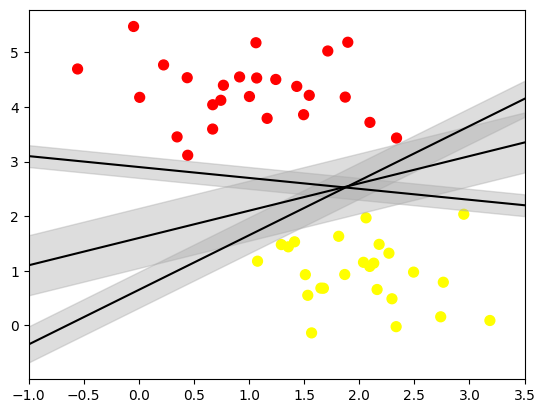

In [4]:
xfit = np.linspace(-1, 3.5)
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')

for m, b, d in [(1, 0.65, 0.33), (0.5, 1.6, 0.55), (-0.2, 2.9, 0.2)]:
    yfit = m * xfit + b
    plt.plot(xfit, yfit, '-k')
    plt.fill_between(xfit, yfit - d, yfit + d, edgecolor='none',
                     color='#AAAAAA', alpha=0.4)

plt.xlim(-1, 3.5)
plt.show()

Dengan menambahkan pita abu-abu di sekitar tiap garis, terlihat bahwa ketiga garis tersebut punya lebar margin yang berbeda-beda. Pita pada garis ketiga paling sempit karena garisnya hampir menyentuh titik data, sedangkan garis kedua mempunyai pita yang paling tebal sebelum menyentuh titik dari salah satu kelas. SVM memilih garis dengan margin terbesar, karena garis seperti itu memberi jarak paling aman dari kedua kelas dan lebih kecil kemungkinannya salah mengklasifikasikan titik baru yang letaknya dekat perbatasan.

## Langkah 5 - Fitting Model

In [5]:
from sklearn.svm import SVC  # "Support vector classifier"
model = SVC(kernel='linear', C=1E10)
model.fit(X, y)

,C,10000000000.0
,kernel,'linear'
,degree,3
,gamma,'scale'
,coef0,0.0
,shrinking,True
,probability,False
,tol,0.001
,cache_size,200
,class_weight,None
,verbose,False


Fungsi bantu untuk memvisualisasikan hasil fitting model.

In [6]:
# buat sebuah fungsi untuk menampilkan fitting data
def plot_svc_decision_function(model, ax=None, plot_support=True):
    if ax is None:
        ax = plt.gca()
    xlim = ax.get_xlim()
    ylim = ax.get_ylim()

    # buat grid untuk evaluasi model
    x = np.linspace(xlim[0], xlim[1], 30)
    y = np.linspace(ylim[0], ylim[1], 30)
    Y, X = np.meshgrid(y, x)
    xy = np.vstack([X.ravel(), Y.ravel()]).T
    P = model.decision_function(xy).reshape(X.shape)

    # plot batas dan margin
    ax.contour(X, Y, P, colors='k',
               levels=[-1, 0, 1], alpha=0.5,
               linestyles=['--', '-', '--'])

    # plot support vectors
    if plot_support:
        ax.scatter(model.support_vectors_[:, 0],
                   model.support_vectors_[:, 1],
                   s=300, linewidth=1, facecolors='none');
    ax.set_xlim(xlim)
    ax.set_ylim(ylim)

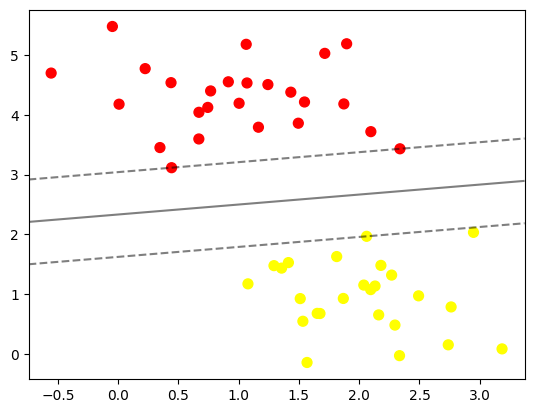

In [7]:
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
plot_svc_decision_function(model)
plt.show()

In [8]:
model.support_vectors_

array([[0.44359863, 3.11530945],
       [2.33812285, 3.43116792],
       [2.06156753, 1.96918596]])

Model dengan `C=1E10` pada dasarnya berperilaku sebagai hard margin, yaitu tidak mentoleransi satu titik pun berada di dalam margin atau di sisi yang salah. Dari 50 titik data, hanya tiga yang menjadi support vector, yaitu titik `[0.4436, 3.1153]`, `[2.3381, 3.4312]`, dan `[2.0616, 1.9692]`. Pada plot, ketiganya adalah titik yang dilingkari dan jatuh tepat pada garis putus-putus margin. Dua titik berasal dari satu kelas dan satu titik dari kelas lainnya. Sisa 47 titik yang berada jauh dari batas tidak ikut menentukan posisi garis sama sekali.

Untuk melihat pengaruh jumlah data terhadap hasil fitting, model dilatih ulang dengan 60 dan 120 data pertama.

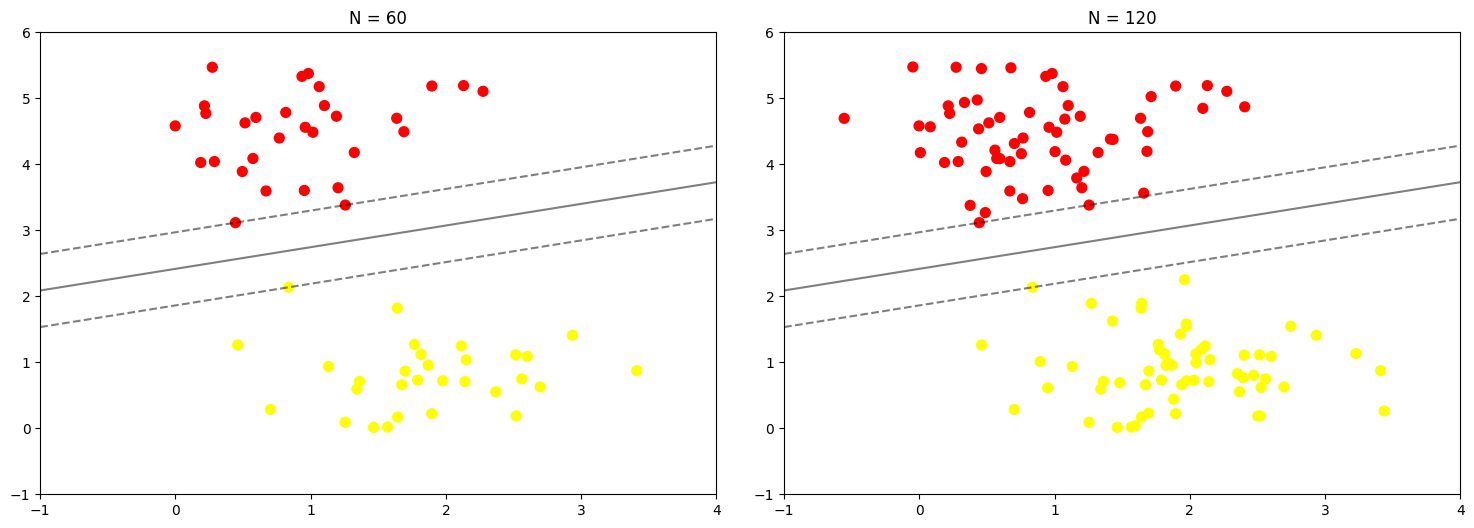

In [9]:
def plot_svm(N=10, ax=None):
    X, y = make_blobs(n_samples=200, centers=2,
                      random_state=0, cluster_std=0.60)
    X = X[:N]
    y = y[:N]
    model = SVC(kernel='linear', C=1E10)
    model.fit(X, y)

    ax = ax or plt.gca()
    ax.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
    ax.set_xlim(-1, 4)
    ax.set_ylim(-1, 6)
    plot_svc_decision_function(model, ax)

fig, ax = plt.subplots(1, 2, figsize=(16, 6))
fig.subplots_adjust(left=0.0625, right=0.95, wspace=0.1)
for axi, N in zip(ax, [60, 120]):
    plot_svm(N, axi)
    axi.set_title('N = {0}'.format(N))
plt.show()

Pada jobsheet bagian terakhir memakai `ipywidgets.interact` untuk memilih jumlah data secara interaktif. Karena hasil notebook ini disimpan dalam bentuk statis, widget tersebut saya ganti dengan dua plot berdampingan untuk `N = 10` dan `N = 200`, sehingga perbandingannya tetap bisa dilihat.

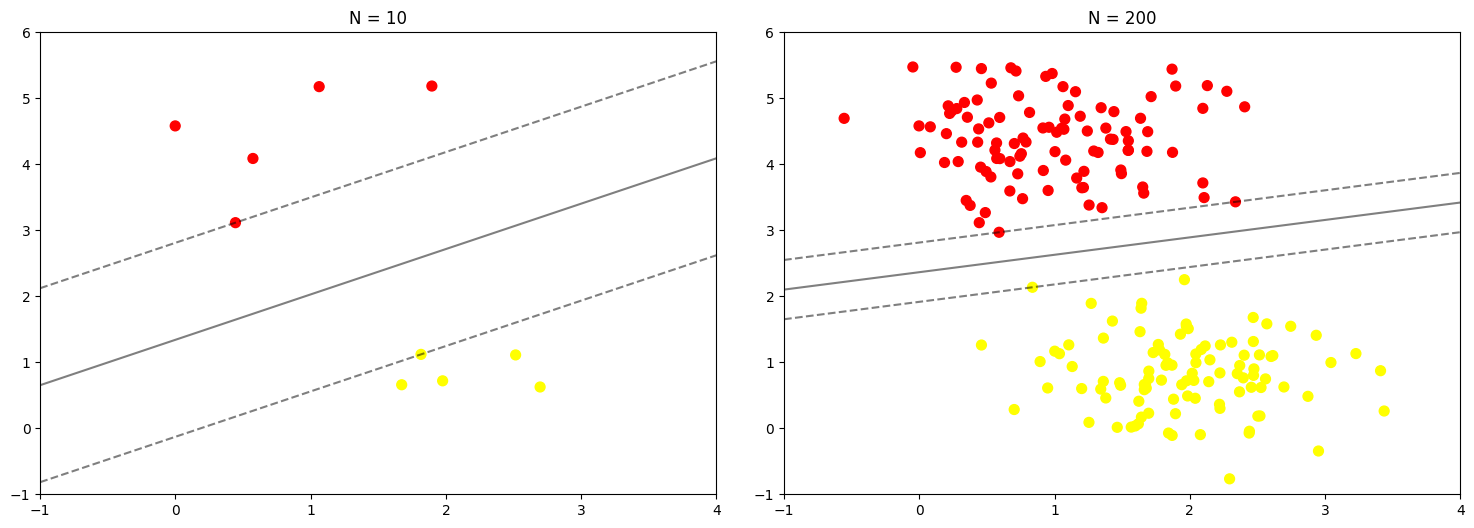

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(16, 6))
fig.subplots_adjust(left=0.0625, right=0.95, wspace=0.1)
for axi, N in zip(ax, [10, 200]):
    plot_svm(N, axi)
    axi.set_title('N = {0}'.format(N))
plt.show()

Supaya perbandingannya tidak hanya berdasarkan tampilan plot, berikut jumlah support vector dan lebar margin $2/\|w\|$ untuk beberapa ukuran data.

In [11]:
import pandas as pd

X_all, y_all = make_blobs(n_samples=200, centers=2,
                          random_state=0, cluster_std=0.60)
baris = []
for N in [10, 60, 120, 200]:
    m = SVC(kernel='linear', C=1E10).fit(X_all[:N], y_all[:N])
    baris.append({
        'N data': N,
        'jumlah support vector': len(m.support_vectors_),
        'lebar margin': round(2 / np.linalg.norm(m.coef_[0]), 4),
        'w': np.round(m.coef_[0], 3),
        'b': round(m.intercept_[0], 3),
    })
pd.DataFrame(baris)

,N data,jumlah support vector,lebar margin,w,b
0,10,2,2.4217,"[0.468, -0.681]",0.913
1,60,3,1.0530,"[0.592, -1.805]",4.360
2,120,3,1.0530,"[0.592, -1.805]",4.360
3,200,3,0.8688,"[0.587, -2.226]",5.264


Pada dua plot dengan `N = 60` dan `N = 120` garis keputusan dan margin terlihat sama persis. Tabel di atas membenarkan hal itu: keduanya menghasilkan tiga support vector, lebar margin `1.053`, serta `w` dan `b` yang identik. Artinya, 60 titik tambahan yang masuk pada `N = 120` jatuh jauh dari batas sehingga tidak ada yang menjadi support vector baru.

Akan tetapi, pernyataan bahwa jumlah data tidak berpengaruh ternyata tidak berlaku untuk semua ukuran. Pada `N = 10` hanya ada dua support vector dan margin masih sangat lebar (`2.4217`) karena datanya terlalu sedikit untuk menggambarkan celah sebenarnya antar kelas. Pada `N = 200` margin menyempit menjadi `0.8688` karena ada titik tambahan yang letaknya lebih dekat ke perbatasan dan mengubah garis. Jadi yang menentukan model bukan banyaknya data, melainkan apakah data baru yang masuk berada di dekat batas kelas atau tidak.

## Kesimpulan Praktikum 1

SVM mencari garis pemisah dengan margin terbesar, bukan sembarang garis yang kebetulan memisahkan data. Pada data dummy linier ini hanya tiga dari 50 titik yang berperan sebagai support vector, dan selama titik tambahan tidak masuk ke area margin, penambahan data (misalnya dari 60 ke 120) tidak mengubah model. Namun hasil perbandingan lengkap menunjukkan model tetap bisa bergeser ketika ada titik baru yang jatuh dekat batas, seperti yang terjadi pada `N = 200`.